In [3]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

In [7]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) >= 1)]
    #filtered_df = filtered_df.loc[:, ['sequence']]
    filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df

# def filter_none_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) == 0)]
#     filtered_df = filtered_df.loc[:, ['sequence']]
#     # filtered_df = filtered_df.loc[:, ['sequence', 'umi_count']]
#     # print("filtered_df_none",filtered_df)
#     return filtered_df

def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='sequence', how='left').fillna(0)
    result_df = result_df.rename(columns={'qseqid_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['sequence'] for name in names]).unique()
    result_df = pd.DataFrame({'sequence': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    result_df.to_csv(os.path.join(base_path, output_file), index=False)
    return result_df

# define the base path for output csv files
base_path = "../../../../5th_9samples_output_18_35_90_90"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR8195524", "SRR8195525", "SRR8195526",
    "SRR8195527", "SRR8195528", "SRR8195529",
    "SRR8195530", "SRR8195531", "SRR8195532"
]

# columns to read from the original CSV files
read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total, base_path, read_columns)


filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


result_df = generate_and_save_result(total_names, df_total_with_match, "dataset5_meet_at_least_one_condition_all_seuquences_90_90.csv")

DataFrame SRR8195524 has 1116861 lines.
DataFrame SRR8195525 has 242017 lines.
DataFrame SRR8195526 has 1090541 lines.
DataFrame SRR8195527 has 1147309 lines.
DataFrame SRR8195528 has 544798 lines.
DataFrame SRR8195529 has 1118199 lines.
DataFrame SRR8195530 has 1489059 lines.
DataFrame SRR8195531 has 1442505 lines.
DataFrame SRR8195532 has 1103621 lines.
{'SRR8195524':                                     sequence  qseqid_count
0             TTTTCCGGGTCGCGGTTCAGTCTCTCACCC         12923
1                       TATCCTGATCGGCTCCACCA           266
2               CCCTGGCCTGAAAGATGGAGCCGGCTCC             1
4                        TGGTCAGATGAATGCGCGC             1
5             CTGCTGTAGCTCAGGGGTAGAGCACTCCCT          1210
...                                      ...           ...
1410084            TCTCGATCCGGTCGGGCAGGGCGCC             1
1410085           ACCGGCGCTCGGCGCGGGCTGCGGTC             1
1410086  AGGTCGTGGAAGTTCGAGTCTTCTCCTGGGAACCA             1
1410088              ATGATGCGCATCGCAC

In [8]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) >= 1)]
    #filtered_df = filtered_df.loc[:, ['sequence']]
    filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df

# def filter_none_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) == 0)]
#     filtered_df = filtered_df.loc[:, ['sequence']]
#     # filtered_df = filtered_df.loc[:, ['sequence', 'umi_count']]
#     # print("filtered_df_none",filtered_df)
#     return filtered_df

def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='sequence', how='left').fillna(0)
    result_df = result_df.rename(columns={'qseqid_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['sequence'] for name in names]).unique()
    result_df = pd.DataFrame({'sequence': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    result_df.to_csv(os.path.join(base_path, output_file), index=False)
    return result_df

# define the base path for output csv files
base_path = "../../../../5th_9samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR8195524", "SRR8195525", "SRR8195526",
    "SRR8195527", "SRR8195528", "SRR8195529",
    "SRR8195530", "SRR8195531", "SRR8195532"
]

# columns to read from the original CSV files
read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total, base_path, read_columns)


filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


result_df_100_100 = generate_and_save_result(total_names, df_total_with_match, "dataset5_meet_at_least_one_condition_all_seuquences_100_100.csv")

DataFrame SRR8195524 has 907727 lines.
DataFrame SRR8195525 has 27591 lines.
DataFrame SRR8195526 has 818567 lines.
DataFrame SRR8195527 has 880830 lines.
DataFrame SRR8195528 has 434568 lines.
DataFrame SRR8195529 has 887957 lines.
DataFrame SRR8195530 has 1161864 lines.
DataFrame SRR8195531 has 1107085 lines.
DataFrame SRR8195532 has 877762 lines.
{'SRR8195524':                                   sequence  qseqid_count
0           TTTTCCGGGTCGCGGTTCAGTCTCTCACCC         12923
2                      TGGTCAGATGAATGCGCGC             1
3           CTGCTGTAGCTCAGGGGTAGAGCACTCCCT          1210
5               CGGGCGTAGCTCAGGGGTAGAGCATA           376
6        GTTCACAACTGACAGTGTTTGCGCGTCATCTAG             2
...                                    ...           ...
1151525            AACCATGGGACCGGGCGAAGAAA             1
1151526             GTCCGTCCGGTTGTCGAAAACA             1
1151528          TCTCGATCCGGTCGGGCAGGGCGCC             1
1151529            ATGATGCGCATCGCACCGGGCGG             1
115153

In [4]:
# define the base path for output csv files
base_path_100 = "../../../../5th_9samples_output"
base_path_90 = "../../../../5th_9samples_output_18_35_90_90"
result_df_100_100 = pd.read_csv(os.path.join(base_path_100, "dataset5_meet_at_least_one_condition_all_seuquences_100_100.csv"), sep=',')
result_df = pd.read_csv(os.path.join(base_path_90, "dataset5_meet_at_least_one_condition_all_seuquences_90_90.csv"), sep=',')
total_names = [
    "SRR8195524", "SRR8195525", "SRR8195526",
    "SRR8195527", "SRR8195528", "SRR8195529",
    "SRR8195530", "SRR8195531", "SRR8195532"
]
df_result_100_100_final = {}
df_result_90_90_final = {}
for name in total_names:
    df_result_100_100_final[name] = set(result_df_100_100[result_df_100_100[name] >= 1]['sequence'])
    df_result_90_90_final[name] = set(result_df[result_df[name] >= 1]['sequence'])

In [5]:

paper_data = {}
for name in total_names:
    if name == 'SRR8195529':
        paper_data[name] = {'TAACGTCTGTCCTTCGGATT', 'CTTGGCAGGCTGGGCGCTCC','TTTTGACTGGATCGGCAACCGTGAT',
                            'TTTGGCGGGGTCGGGAACC','ATCCTCTCCCCGCAACCA','ATTGGCGTCACAGATCAGGGGCAT','GAAATCCCTGATCGCGCAG',
                            'ACAAATCTCGGCAAGGCC','CGAACTCTGCACCAAGGC','CGAATCTCTCATCACCCACCA','AAACCGGATCCTGCAGCC'}
    if name == 'SRR8195530':
        paper_data[name] =   {'TCACCGGTTGGGAAGGCGCTGA','CTTCCCGCCCCATGGCCGA','AATTAATGGGTCCTGACC','TTTCGGGTGGGCAGCGCC',
                                'CGCATGGGCGGAGCTTTTCGTTAG','AATTAATGGGTCCTGACC','ATTGATTGCGGCCATCCG','CAAGAACCGCCATCTGCATGCC',
                                'ATGCTTTTTGGCCGCATT','CGAGGTCGAACATGATGAA','ATGTTGCCGGTGCGGCGGCGGGC'}
    if name == 'SRR8195531':
        paper_data[name] =   {'CCGAGGTCCGGTATCGCCTGACT','ATCGTGGCCGCACTGGAGCC','CGCGCAGGCGGGGATCTCGAGC','ATCGCTGCGGGCAATAAAAGACC',
                                'TTACCCGTGAGGTCGGCTGTGCGAT','ATAATGACGTCCGTTGCGAC','AAACGGGGTCGGGGGGCTG','ACCACAGGTGCGGGCATGGGCATG',
                                'AAAGCCCCGGCGCGATTGTCC','TTTGCGCGATGGGTCCCTGAT','TCACAGTCGAGACGCTCTCTCACC'}

    if name == 'SRR8195532':
        paper_data[name] =   {'ATAAGGAGTAGGCGAATGAGC','TCACAGTCGAGACGCTCTCTCACC','CTTGGCGTCGAAGGCATGA','TTTGGCAAGGCACAGCGCGCAG','CTGCGCGCTGTGCCTTGCC'}

    if name == 'SRR8195525':
        paper_data[name] =   {'ATCTTTCGATGGTCGTGGCA','CCAAGCGCGGTGCGGACCG','ATGGGCATCCTGACCGAAGGCACG','CTTGAAGACCTGCATCAGCGTTC'}

    if name == 'SRR8195526':
        paper_data[name] =   {'ACGAATAGCATGTCGATGGC','ATCGCCTGAACGCGCGCCTGACCG','GTCCGGTGGTCTGGGCACCATG','ATCCTGCCCCCGCAACCA',
                                'CTATGCAGACACCCCGGAC','ATCACGTTGAGCCAAAAGAAAAGC','ATACAACTGATGTCGCCTGC','ATCCTCGGAATAGGTATAGGCTTCC',
                                'ATCAATCGCCGGGATCATGATCCC','ATATACGGCCTGGCATAATC','TTTGCGGAATGCCACCCGGCAACG','GTGTTCTTTTGGTCGCGCATGCCG',
                                'AAAAGACCGTCCTGCCACCG','CTCCTGAGCCGGGCCAAT'}

    if name == 'SRR8195527':
        paper_data[name] =   {'ATAATGACGTCCGTTGCGA','TTCAAGTCTGATGCCCGCGCC','GTCCGGTGGTCTGGGCACCATG','GCAGTGGCTTGGCGGGATCGGGAT',
                                'GGGCCGAGATCGAAAGCAACACG','ATCCTGCCCCCGCAACCA','TTTGTCGTTCTGGGCTGGCA','ATTGATATCGCATCGGTTACCGA','GTATATTGCCAATTTTGT'}

    if name == 'SRR8195528':
        paper_data[name] =   {'CTTGCCGCCGGTATGCTCGCATC','ATGCAGATCGGTTTGCGCACC','ACGGTTTGCGTCGGTCACGCTGGC','ATGGACTCCCGCTTTCGC',
                                'ATTTGCATGCCCGTCTGGC','AGCATTCAAGCATCGGCGGGAT'}
    
    if name == 'SRR8195524':
        paper_data[name] =   {'TAGGCGGGAGTCCACCGGGC','GGATCAGCTGGGTAACATC','CTTGCACCGGGCCGCTTTCGGATG','ACGCGACCGCGGCAAGGAAA',
                                'AAAGCAGGAAGAATACGAACAGA','ATGCACCCGGACCGAAACCC','AAAGCGCGCCCCCTTGCTCCC','ATTCAGGAATCTGTTCTGACGCAGC',
                                'ATTTTAGTCCGCGTCGCAAC','CAAACAGCTGAAGGCCTCCC','ATTCCGATGATCTGGTGATTG','TTGCCGATCATCGCCCTTGCCCTG',
                                'CTTCAGTTCCTCGACCTT','CTGACTGGATTCCCGCGT','ATCATGCCGGGCAGATCA'}




# # our_method_100_100 = set(df['column_name'])
# for name in total_names:
#     # Draw the Venn diagram
#     venn2([paper_data[name], df_result_100_100_final[name]], set_labels=('paper', 'metasrna'))
#     # Move the left-circle label (id='10') a bit to the left
#     label = venn2.get_label_by_id('10')
#     if label:
#         # print("label")
#         x, y = label.get_position()
#         print(x)
#         label.set_position((x - 1, y + 5))  # adjust as needed
#     label = venn2.get_label_by_id('01')
#     if label:
#         print("label")
#         x, y = label.get_position()
#         print(x)
#         label.set_position((x - 5, y + 5))  # adjust as needed
# # Move other labels if needed
# # venn.get_label_by_id('01').set_position(...)
# # venn.get_label_by_id('11').set_position(...)

# plt.title("Venn Diagram of founded miRNAs")
# plt.show()


aaa


/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:62: UserWarning: venn3_unweighted is deprecated. Use venn3 with the appropriate layout_algorithm instead.
  warnings.warn(


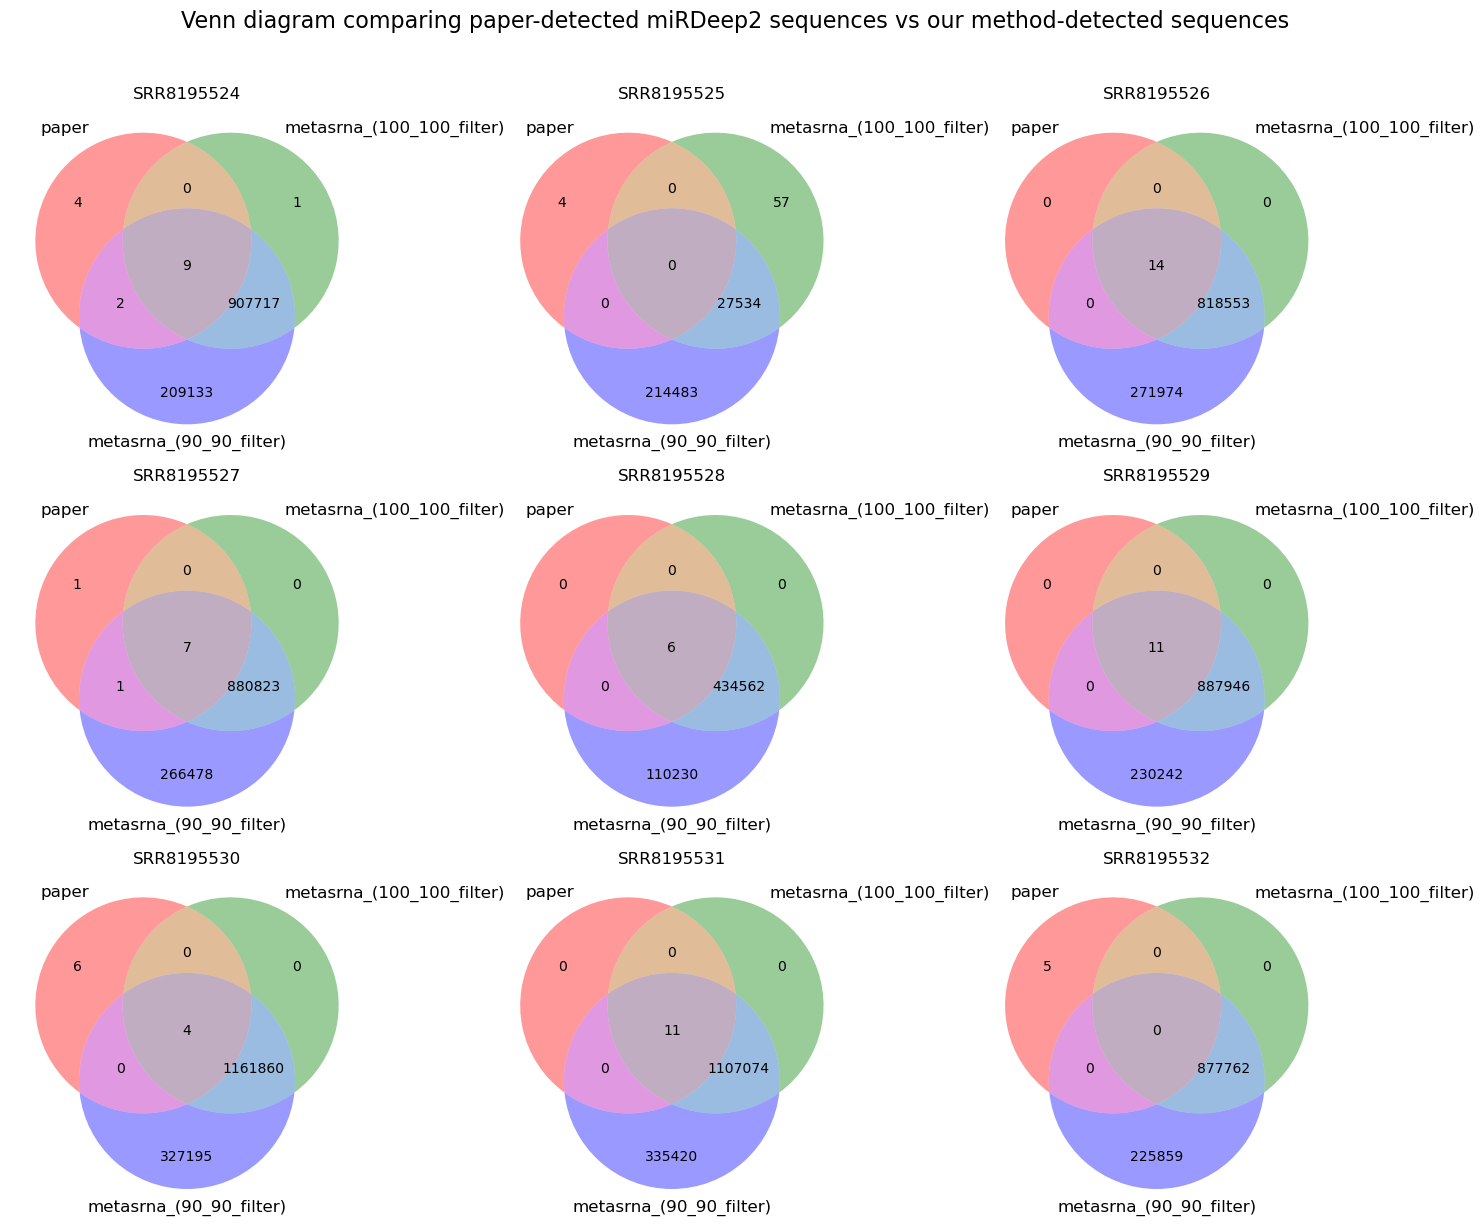

In [6]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted
from matplotlib_venn import venn3_unweighted

print("aaa")


fig, axes = plt.subplots(3, 3, figsize=(15, 12))  # 3x3 grid
fig.suptitle(
    "Venn diagram comparing paper-detected miRDeep2 sequences vs our method-detected sequences",
    fontsize=16,
    y=1.02  # move up if needed
)

axes = axes.flatten()

for i, name in enumerate(total_names[:9]):
    ax = axes[i]
    plt.sca(ax)
    # if name == "SRR8195529":
    venn = venn3_unweighted([paper_data[name], df_result_100_100_final[name], df_result_90_90_final[name]],
                set_labels=('paper','metasrna_(100_100_filter)', 'metasrna_(90_90_filter)'))


    # if venn.get_patch_by_id('10'):
    #     venn.get_patch_by_id('10').set_color('skyblue')
    # if venn.get_patch_by_id('01'):
    #     venn.get_patch_by_id('01').set_color('lightgreen')
    # if venn.get_patch_by_id('11'):
    #     venn.get_patch_by_id('11').set_color('gray')


    # for label_id, dx, dy in [('10', -0.2, 0.05), ('01', 0.2, 0.05), ('11', 0, -0.05)]:
    #     label = venn.get_label_by_id(label_id)
    #     if label:
    #         x, y = label.get_position()
    #         label.set_position((x + dx, y + dy))

    ax.set_title(name)



for j in range(len(total_names), 9):
    fig.delaxes(axes[j])


# plt.grid(True)
# plt.grid(True, color="lightgray", linewidth=0.1)
# ax.legend(prop=arial_font, title="Groups", title_fontproperties=arial_font)
# plt.show()
plt.savefig("supp_figure2.pdf", format="pdf", bbox_inches="tight")
plt.tight_layout()
plt.show()

aaa


/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:62: UserWarning: venn3_unweighted is deprecated. Use venn3 with the appropriate layout_algorithm instead.
  warnings.warn(


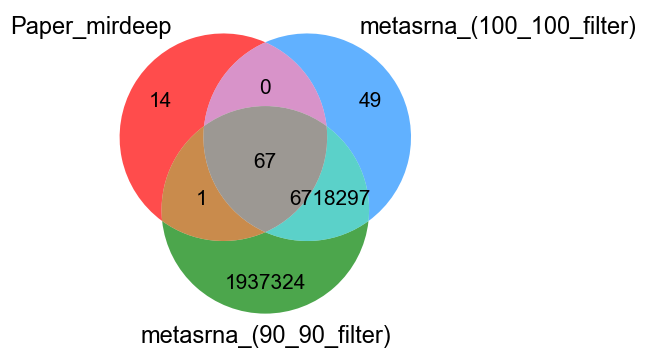

In [52]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from matplotlib_venn import venn3_unweighted
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=15)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=17)
print("aaa")
paper = {'TAACGTCTGTCCTTCGGATT', 'CTTGGCAGGCTGGGCGCTCC','TTTTGACTGGATCGGCAACCGTGAT',
'TTTGGCGGGGTCGGGAACC','ATCCTCTCCCCGCAACCA','ATTGGCGTCACAGATCAGGGGCAT','GAAATCCCTGATCGCGCAG',
'ACAAATCTCGGCAAGGCC','CGAACTCTGCACCAAGGC','CGAATCTCTCATCACCCACCA','AAACCGGATCCTGCAGCC',


'TCACCGGTTGGGAAGGCGCTGA','CTTCCCGCCCCATGGCCGA','AATTAATGGGTCCTGACC','TTTCGGGTGGGCAGCGCC',
'CGCATGGGCGGAGCTTTTCGTTAG','AATTAATGGGTCCTGACC','ATTGATTGCGGCCATCCG','CAAGAACCGCCATCTGCATGCC',
'ATGCTTTTTGGCCGCATT','CGAGGTCGAACATGATGAA','ATGTTGCCGGTGCGGCGGCGGGC',

'CCGAGGTCCGGTATCGCCTGACT','ATCGTGGCCGCACTGGAGCC','CGCGCAGGCGGGGATCTCGAGC','ATCGCTGCGGGCAATAAAAGACC',
'TTACCCGTGAGGTCGGCTGTGCGAT','ATAATGACGTCCGTTGCGAC','AAACGGGGTCGGGGGGCTG','ACCACAGGTGCGGGCATGGGCATG',
'AAAGCCCCGGCGCGATTGTCC','TTTGCGCGATGGGTCCCTGAT','TCACAGTCGAGACGCTCTCTCACC',

'ATAAGGAGTAGGCGAATGAGC','TCACAGTCGAGACGCTCTCTCACC','CTTGGCGTCGAAGGCATGA','TTTGGCAAGGCACAGCGCGCAG','CTGCGCGCTGTGCCTTGCC',

'ATCTTTCGATGGTCGTGGCA','CCAAGCGCGGTGCGGACCG','ATGGGCATCCTGACCGAAGGCACG','CTTGAAGACCTGCATCAGCGTTC',

'ACGAATAGCATGTCGATGGC','ATCGCCTGAACGCGCGCCTGACCG','GTCCGGTGGTCTGGGCACCATG','ATCCTGCCCCCGCAACCA',
'CTATGCAGACACCCCGGAC','ATCACGTTGAGCCAAAAGAAAAGC','ATACAACTGATGTCGCCTGC','ATCCTCGGAATAGGTATAGGCTTCC',
'ATCAATCGCCGGGATCATGATCCC','ATATACGGCCTGGCATAATC','TTTGCGGAATGCCACCCGGCAACG','GTGTTCTTTTGGTCGCGCATGCCG',
'AAAAGACCGTCCTGCCACCG','CTCCTGAGCCGGGCCAAT',

'ATAATGACGTCCGTTGCGA','TTCAAGTCTGATGCCCGCGCC','GTCCGGTGGTCTGGGCACCATG','GCAGTGGCTTGGCGGGATCGGGAT',
'GGGCCGAGATCGAAAGCAACACG','ATCCTGCCCCCGCAACCA','TTTGTCGTTCTGGGCTGGCA','ATTGATATCGCATCGGTTACCGA','GTATATTGCCAATTTTGT',

'CTTGCCGCCGGTATGCTCGCATC','ATGCAGATCGGTTTGCGCACC','ACGGTTTGCGTCGGTCACGCTGGC','ATGGACTCCCGCTTTCGC',
'ATTTGCATGCCCGTCTGGC','AGCATTCAAGCATCGGCGGGAT',

'TAGGCGGGAGTCCACCGGGC','GGATCAGCTGGGTAACATC','CTTGCACCGGGCCGCTTTCGGATG','ACGCGACCGCGGCAAGGAAA',
'AAAGCAGGAAGAATACGAACAGA','ATGCACCCGGACCGAAACCC','AAAGCGCGCCCCCTTGCTCCC','ATTCAGGAATCTGTTCTGACGCAGC',
'ATTTTAGTCCGCGTCGCAAC','CAAACAGCTGAAGGCCTCCC','ATTCCGATGATCTGGTGATTG','TTGCCGATCATCGCCCTTGCCCTG',
'CTTCAGTTCCTCGACCTT','CTGACTGGATTCCCGCGT','ATCATGCCGGGCAGATCA'}

plt.figure(figsize=(6, 6))
ve = venn3_unweighted([paper, set(result_df_100_100['sequence']),set(result_df['sequence'])], set_colors=("red", "#1E90FF", "green"),set_labels=('Paper_mirdeep', 'metasrna_(100_100_filter)', 'metasrna_(90_90_filter)'),alpha=0.7)
for label in ve.set_labels:
    label.set_fontproperties(arial_font_in)


for label in ve.subset_labels:
    if label:  # some can be None
        label.set_fontproperties(arial_font)
#plt.title("Venn diagram comparing miRDeep2 sequences vs our method-detected sequences",fontproperties=arial_font_in)
plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)
plt.tight_layout()
# plt.grid(True)
# plt.grid(True, color="lightgray", linewidth=0.1)
# ax.legend(prop=arial_font, title="Groups", title_fontproperties=arial_font)
# plt.show()
plt.savefig("figure3_C.pdf", format="pdf", bbox_inches="tight")

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


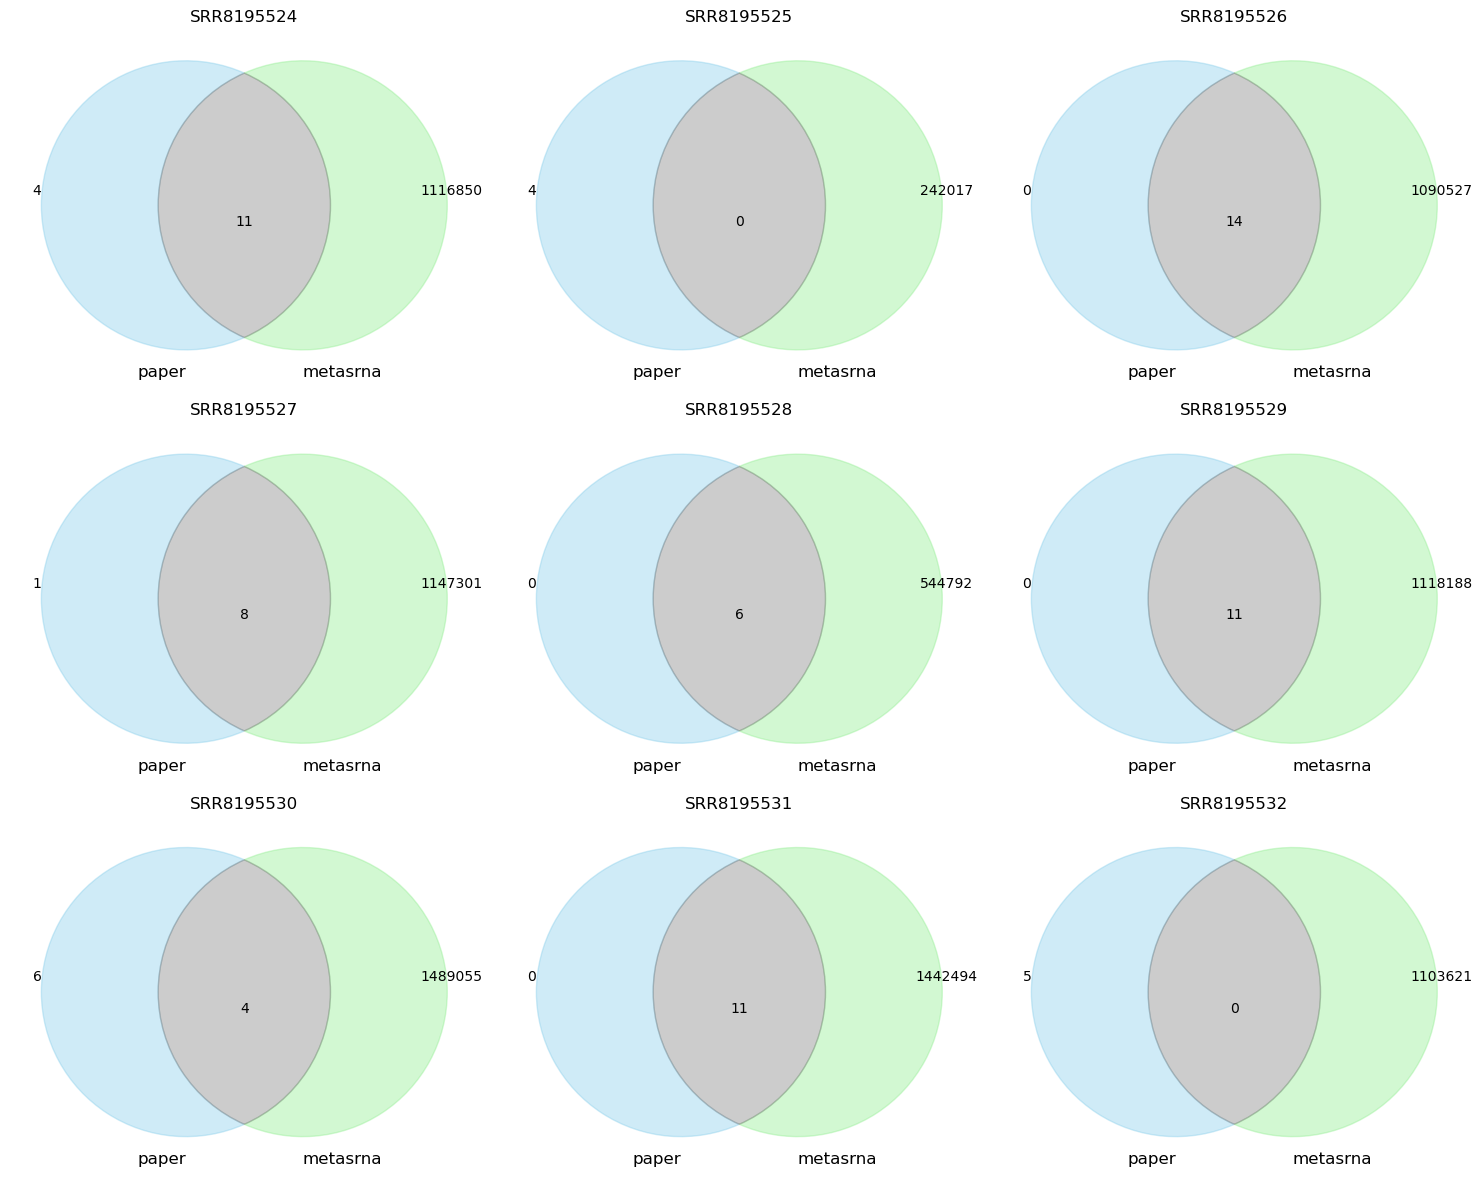

In [13]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted


fig, axes = plt.subplots(3, 3, figsize=(15, 12))  

axes = axes.flatten()

for i, name in enumerate(total_names[:9]):
    ax = axes[i]
    plt.sca(ax)
    venn = venn2_unweighted([paper_data[name], df_result_90_90_final[name]],
                 set_labels=('paper', 'metasrna'))

    if venn.get_patch_by_id('10'):
        venn.get_patch_by_id('10').set_color('skyblue')
    if venn.get_patch_by_id('01'):
        venn.get_patch_by_id('01').set_color('lightgreen')
    if venn.get_patch_by_id('11'):
        venn.get_patch_by_id('11').set_color('gray')

    for label_id, dx, dy in [('10', -0.2, 0.05), ('01', 0.2, 0.05), ('11', 0, -0.05)]:
        label = venn.get_label_by_id(label_id)
        if label:
            x, y = label.get_position()
            label.set_position((x + dx, y + dy))

    ax.set_title(name)


for j in range(len(total_names), 9):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [14]:

only_A = len(paper - our_method)
print(only_A)

only_b = len(our_method - paper)
print(only_b)



NameError: name 'our_method' is not defined

In [ ]:
paper = {'TAACGTCTGTCCTTCGGATT', 'CTTGGCAGGCTGGGCGCTCC','TTTTGACTGGATCGGCAACCGTGAT',
'TTTGGCGGGGTCGGGAACC','ATCCTCTCCCCGCAACCA','ATTGGCGTCACAGATCAGGGGCAT','GAAATCCCTGATCGCGCAG',
'ACAAATCTCGGCAAGGCC','CGAACTCTGCACCAAGGC','CGAATCTCTCATCACCCACCA','AAACCGGATCCTGCAGCC',


'TCACCGGTTGGGAAGGCGCTGA','CTTCCCGCCCCATGGCCGA','AATTAATGGGTCCTGACC','TTTCGGGTGGGCAGCGCC',
'CGCATGGGCGGAGCTTTTCGTTAG','AATTAATGGGTCCTGACC','ATTGATTGCGGCCATCCG','CAAGAACCGCCATCTGCATGCC',
'ATGCTTTTTGGCCGCATT','CGAGGTCGAACATGATGAA','ATGTTGCCGGTGCGGCGGCGGGC',

'CCGAGGTCCGGTATCGCCTGACT','ATCGTGGCCGCACTGGAGCC','CGCGCAGGCGGGGATCTCGAGC','ATCGCTGCGGGCAATAAAAGACC',
'TTACCCGTGAGGTCGGCTGTGCGAT','ATAATGACGTCCGTTGCGAC','AAACGGGGTCGGGGGGCTG','ACCACAGGTGCGGGCATGGGCATG',
'AAAGCCCCGGCGCGATTGTCC','TTTGCGCGATGGGTCCCTGAT','TCACAGTCGAGACGCTCTCTCACC',

'ATAAGGAGTAGGCGAATGAGC','TCACAGTCGAGACGCTCTCTCACC','CTTGGCGTCGAAGGCATGA','TTTGGCAAGGCACAGCGCGCAG','CTGCGCGCTGTGCCTTGCC',

'ATCTTTCGATGGTCGTGGCA','CCAAGCGCGGTGCGGACCG','ATGGGCATCCTGACCGAAGGCACG','CTTGAAGACCTGCATCAGCGTTC',

'ACGAATAGCATGTCGATGGC','ATCGCCTGAACGCGCGCCTGACCG','GTCCGGTGGTCTGGGCACCATG','ATCCTGCCCCCGCAACCA',
'CTATGCAGACACCCCGGAC','ATCACGTTGAGCCAAAAGAAAAGC','ATACAACTGATGTCGCCTGC','ATCCTCGGAATAGGTATAGGCTTCC',
'ATCAATCGCCGGGATCATGATCCC','ATATACGGCCTGGCATAATC','TTTGCGGAATGCCACCCGGCAACG','GTGTTCTTTTGGTCGCGCATGCCG',
'AAAAGACCGTCCTGCCACCG','CTCCTGAGCCGGGCCAAT',

'ATAATGACGTCCGTTGCGA','TTCAAGTCTGATGCCCGCGCC','GTCCGGTGGTCTGGGCACCATG','GCAGTGGCTTGGCGGGATCGGGAT',
'GGGCCGAGATCGAAAGCAACACG','ATCCTGCCCCCGCAACCA','TTTGTCGTTCTGGGCTGGCA','ATTGATATCGCATCGGTTACCGA','GTATATTGCCAATTTTGT',

'CTTGCCGCCGGTATGCTCGCATC','ATGCAGATCGGTTTGCGCACC','ACGGTTTGCGTCGGTCACGCTGGC','ATGGACTCCCGCTTTCGC',
'ATTTGCATGCCCGTCTGGC','AGCATTCAAGCATCGGCGGGAT',

'TAGGCGGGAGTCCACCGGGC','GGATCAGCTGGGTAACATC','CTTGCACCGGGCCGCTTTCGGATG','ACGCGACCGCGGCAAGGAAA',
'AAAGCAGGAAGAATACGAACAGA','ATGCACCCGGACCGAAACCC','AAAGCGCGCCCCCTTGCTCCC','ATTCAGGAATCTGTTCTGACGCAGC',
'ATTTTAGTCCGCGTCGCAAC','CAAACAGCTGAAGGCCTCCC','ATTCCGATGATCTGGTGATTG','TTGCCGATCATCGCCCTTGCCCTG',
'CTTCAGTTCCTCGACCTT','CTGACTGGATTCCCGCGT','ATCATGCCGGGCAGATCA'}
print(len(paper))

In [ ]:
# paper_list = ['TAACGTCTGTCCTTCGGATT', 'CTTGGCAGGCTGGGCGCTCC','TTTTGACTGGATCGGCAACCGTGAT',
# 'TTTGGCGGGGTCGGGAACC','ATCCTCTCCCCGCAACCA','ATTGGCGTCACAGATCAGGGGCAT','GAAATCCCTGATCGCGCAG',
# 'ACAAATCTCGGCAAGGCC','CGAACTCTGCACCAAGGC','CGAATCTCTCATCACCCACCA','AAACCGGATCCTGCAGCC',


# 'TCACCGGTTGGGAAGGCGCTGA','CTTCCCGCCCCATGGCCGA','AATTAATGGGTCCTGACC','TTTCGGGTGGGCAGCGCC',
# 'CGCATGGGCGGAGCTTTTCGTTAG','AATTAATGGGTCCTGACC','ATTGATTGCGGCCATCCG','CAAGAACCGCCATCTGCATGCC',
# 'ATGCTTTTTGGCCGCATT','CGAGGTCGAACATGATGAA','ATGTTGCCGGTGCGGCGGCGGGC',

# 'CCGAGGTCCGGTATCGCCTGACT','ATCGTGGCCGCACTGGAGCC','CGCGCAGGCGGGGATCTCGAGC','ATCGCTGCGGGCAATAAAAGACC',
# 'TTACCCGTGAGGTCGGCTGTGCGAT','ATAATGACGTCCGTTGCGAC','AAACGGGGTCGGGGGGCTG','ACCACAGGTGCGGGCATGGGCATG',
# 'AAAGCCCCGGCGCGATTGTCC','TTTGCGCGATGGGTCCCTGAT','TCACAGTCGAGACGCTCTCTCACC',

# 'ATAAGGAGTAGGCGAATGAGC','TCACAGTCGAGACGCTCTCTCACC','CTTGGCGTCGAAGGCATGA','TTTGGCAAGGCACAGCGCGCAG','CTGCGCGCTGTGCCTTGCC',

# 'ATCTTTCGATGGTCGTGGCA','CCAAGCGCGGTGCGGACCG','ATGGGCATCCTGACCGAAGGCACG','CTTGAAGACCTGCATCAGCGTTC',

# 'ACGAATAGCATGTCGATGGC','ATCGCCTGAACGCGCGCCTGACCG','GTCCGGTGGTCTGGGCACCATG','ATCCTGCCCCCGCAACCA',
# 'CTATGCAGACACCCCGGAC','ATCACGTTGAGCCAAAAGAAAAGC','ATACAACTGATGTCGCCTGC','ATCCTCGGAATAGGTATAGGCTTCC',
# 'ATCAATCGCCGGGATCATGATCCC','ATATACGGCCTGGCATAATC','TTTGCGGAATGCCACCCGGCAACG','GTGTTCTTTTGGTCGCGCATGCCG',
# 'AAAAGACCGTCCTGCCACCG','CTCCTGAGCCGGGCCAAT',

# 'ATAATGACGTCCGTTGCGA','TTCAAGTCTGATGCCCGCGCC','GTCCGGTGGTCTGGGCACCATG','GCAGTGGCTTGGCGGGATCGGGAT',
# 'GGGCCGAGATCGAAAGCAACACG','ATCCTGCCCCCGCAACCA','TTTGTCGTTCTGGGCTGGCA','ATTGATATCGCATCGGTTACCGA','GTATATTGCCAATTTTGT',

# 'CTTGCCGCCGGTATGCTCGCATC','ATGCAGATCGGTTTGCGCACC','ACGGTTTGCGTCGGTCACGCTGGC','ATGGACTCCCGCTTTCGC',
# 'ATTTGCATGCCCGTCTGGC','AGCATTCAAGCATCGGCGGGAT',

# 'TAGGCGGGAGTCCACCGGGC','GGATCAGCTGGGTAACATC','CTTGCACCGGGCCGCTTTCGGATG','ACGCGACCGCGGCAAGGAAA',
# 'AAAGCAGGAAGAATACGAACAGA','ATGCACCCGGACCGAAACCC','AAAGCGCGCCCCCTTGCTCCC','ATTCAGGAATCTGTTCTGACGCAGC',
# 'ATTTTAGTCCGCGTCGCAAC','CAAACAGCTGAAGGCCTCCC','ATTCCGATGATCTGGTGATTG','TTGCCGATCATCGCCCTTGCCCTG',
# 'CTTCAGTTCCTCGACCTT','CTGACTGGATTCCCGCGT','ATCATGCCGGGCAGATCA']
# print(len(paper_list))

synthetic data: (977 sequences venn diagram is compared with fixed length:16-25 among all tags)

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


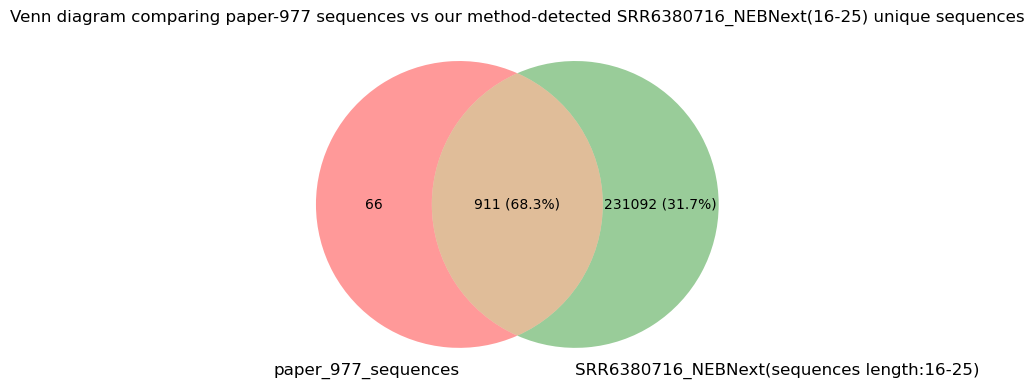

In [18]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted
5705178/8351124
plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("66","231092 (31.7%)","911 (68.3%)")
, set_labels=('paper_977_sequences', 'SRR6380716_NEBNext(sequences length:16-25)'),set_colors=("red", "green"))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")
plt.title("Venn diagram comparing paper-977 sequences vs our method-detected SRR6380716_NEBNext(16-25) unique sequences")
plt.savefig("supp_figure1_test3.pdf", format="pdf", bbox_inches="tight")
#plt.show()

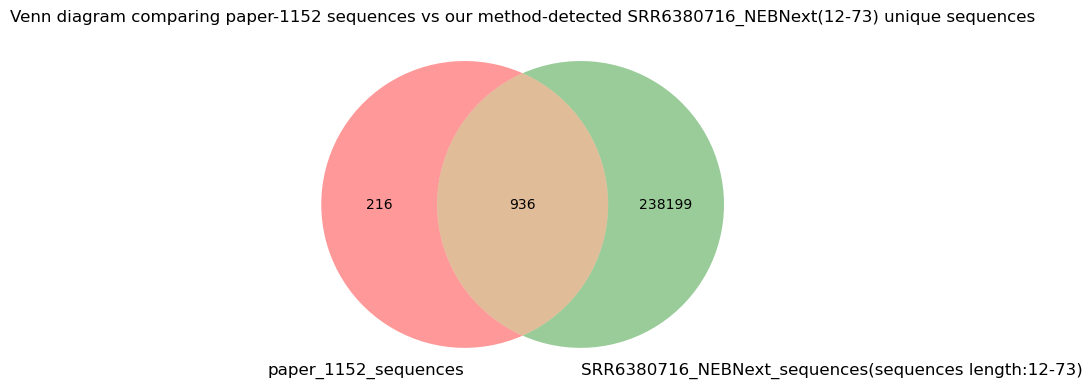

In [ ]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted

plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("216","238199","936")
, set_labels=('paper_1152_sequences', 'SRR6380716_NEBNext_sequences(sequences length:12-73)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")
plt.title("Venn diagram comparing paper-1152 sequences vs our method-detected SRR6380716_NEBNext(12-73) unique sequences")
plt.show()

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


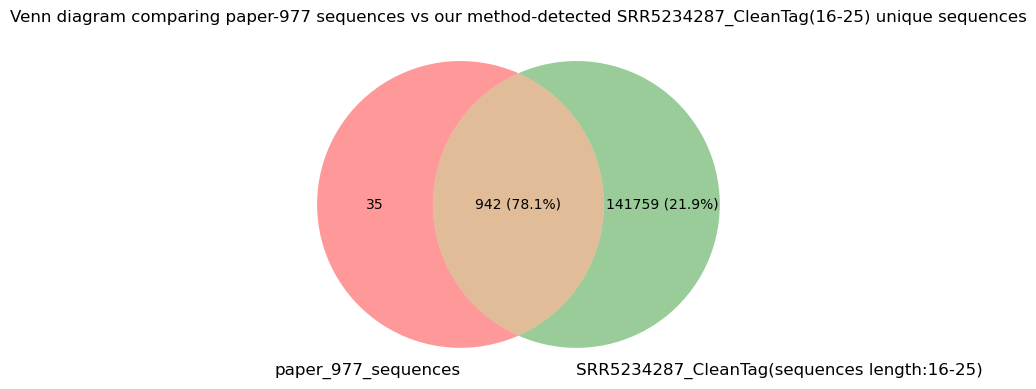

In [16]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted
7060412/9040011
plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("35","141759 (21.9%)","942 (78.1%)")
, set_labels=('paper_977_sequences', 'SRR5234287_CleanTag(sequences length:16-25)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")
plt.title("Venn diagram comparing paper-977 sequences vs our method-detected SRR5234287_CleanTag(16-25) unique sequences")
plt.savefig("supp_figure1_test1.pdf", format="pdf", bbox_inches="tight")

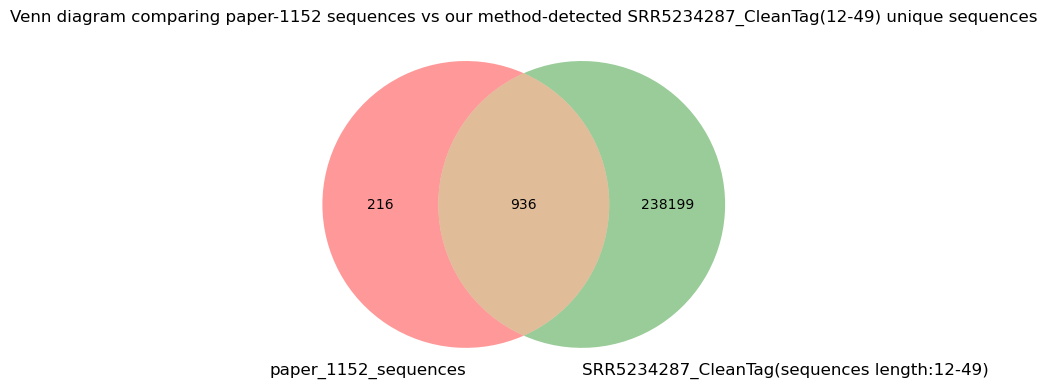

In [ ]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted

plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("182","155559","970")
, set_labels=('paper_1152_sequences', 'SRR5234287_CleanTag(sequences length:12-49)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")
plt.title("Venn diagram comparing paper-1152 sequences vs our method-detected SRR5234287_CleanTag(12-49) unique sequences")
plt.show()

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


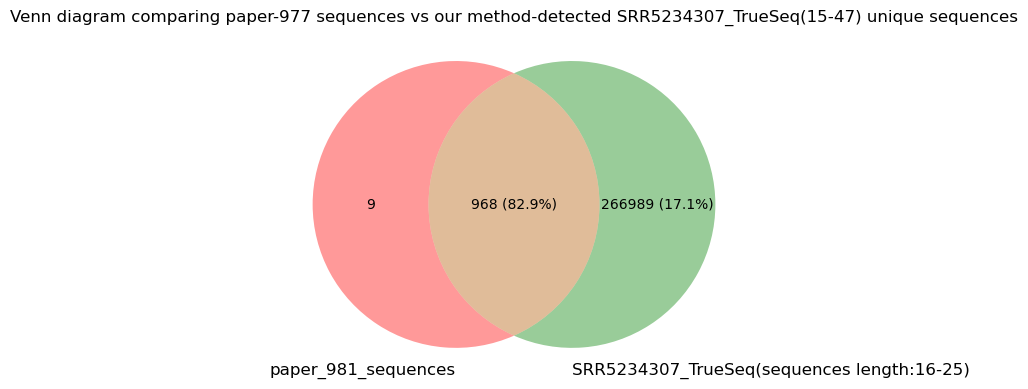

In [20]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted
10470553/12623964
plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("9","266989 (17.1%)","968 (82.9%)")
, set_labels=('paper_981_sequences', 'SRR5234307_TrueSeq(sequences length:16-25)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")
plt.title("Venn diagram comparing paper-977 sequences vs our method-detected SRR5234307_TrueSeq(15-47) unique sequences")
plt.savefig("supp_figure1_test4.pdf", format="pdf", bbox_inches="tight")

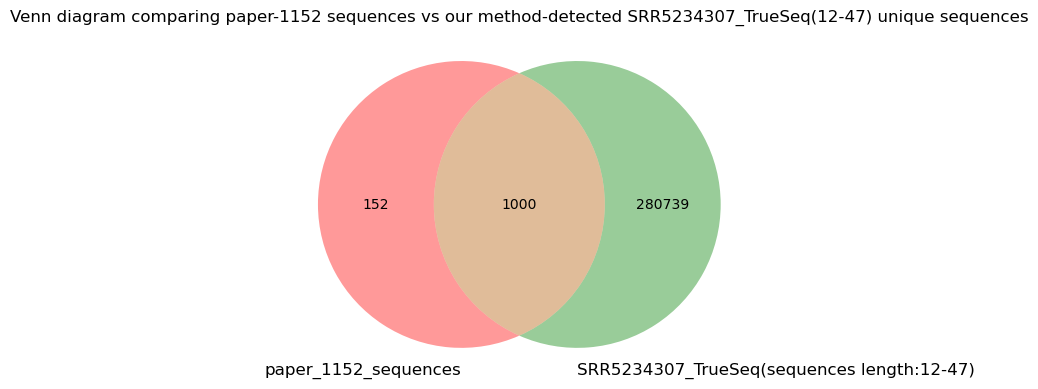

In [ ]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted

plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("152","280739","1000")
, set_labels=('paper_1152_sequences', 'SRR5234307_TrueSeq(sequences length:12-47)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")
plt.title("Venn diagram comparing paper-1152 sequences vs our method-detected SRR5234307_TrueSeq(12-47) unique sequences")
plt.show()

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


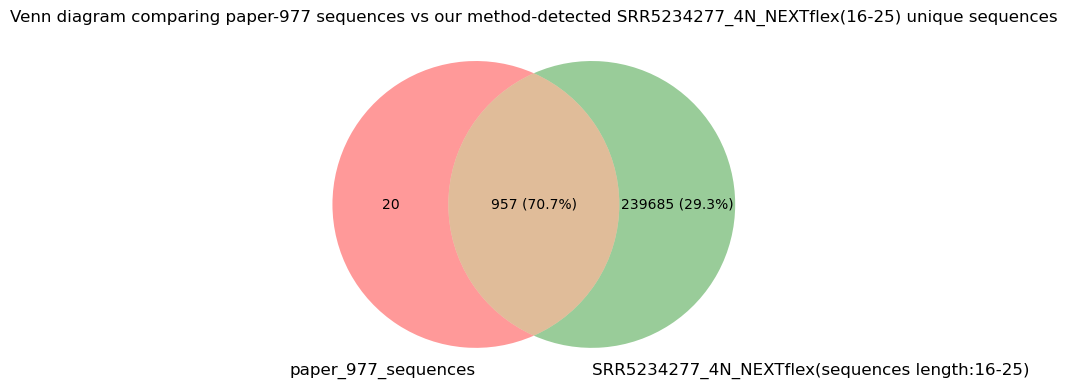

In [21]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted
9270892/13111264
plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("20","239685 (29.3%)","957 (70.7%)")
, set_labels=('paper_977_sequences', 'SRR5234277_4N_NEXTflex(sequences length:16-25)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")
plt.title("Venn diagram comparing paper-977 sequences vs our method-detected SRR5234277_4N_NEXTflex(16-25) unique sequences")
plt.savefig("supp_figure1_test5.pdf", format="pdf", bbox_inches="tight")

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


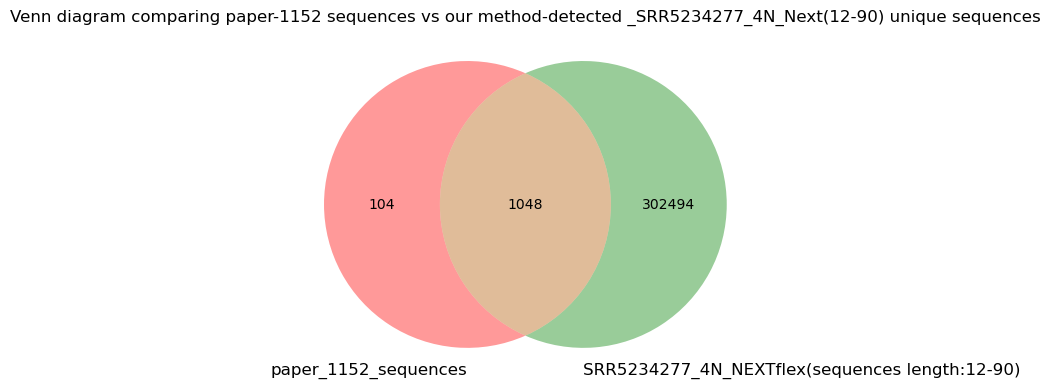

In [ ]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted

plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("104","302494","1048")
, set_labels=('paper_1152_sequences', 'SRR5234277_4N_NEXTflex(sequences length:12-90)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")
plt.title("Venn diagram comparing paper-1152 sequences vs our method-detected _SRR5234277_4N_Next(12-90) unique sequences")
plt.show()

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


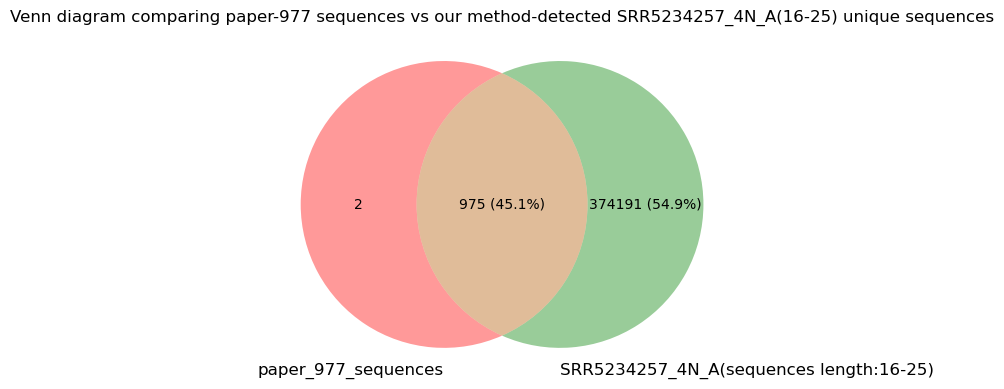

In [22]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted
4905875/10879366
plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("2","374191 (54.9%)","975 (45.1%)")
, set_labels=('paper_977_sequences', 'SRR5234257_4N_A(sequences length:16-25)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")

plt.title("Venn diagram comparing paper-977 sequences vs our method-detected SRR5234257_4N_A(16-25) unique sequences")

# plt.show()
plt.savefig("supp_figure1_test2.pdf", format="pdf", bbox_inches="tight")

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


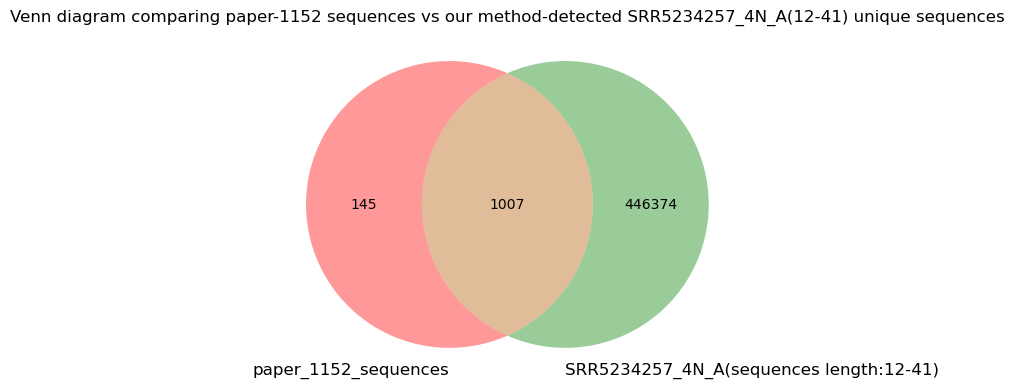

In [ ]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted

plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("145","446374","1007")
, set_labels=('paper_1152_sequences', 'SRR5234257_4N_A(sequences length:12-41)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")

plt.title("Venn diagram comparing paper-1152 sequences vs our method-detected SRR5234257_4N_A(12-41) unique sequences")
plt.show()

/home/yaolab/mzhou10/.conda/envs/pydeseq2/lib/python3.12/site-packages/matplotlib_venn/_util.py:32: UserWarning: venn2_unweighted is deprecated. Use venn2 with the appropriate layout_algorithm instead.
  warnings.warn(


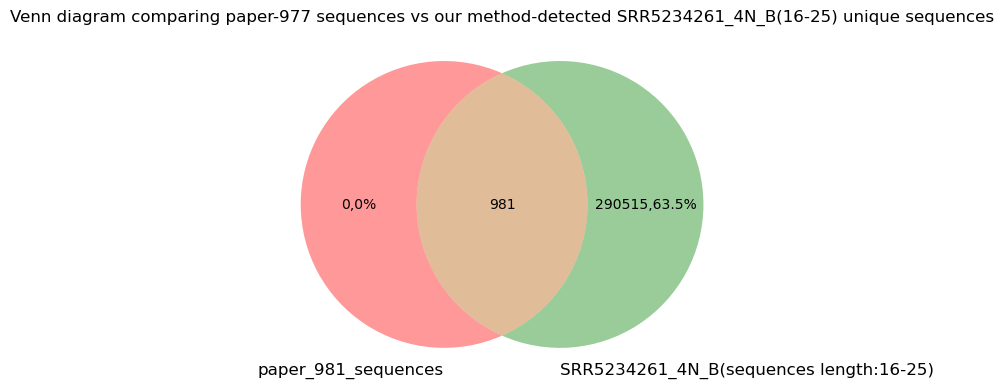

In [ ]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted

plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("0,0%","290515,63.5%","981")
, set_labels=('paper_981_sequences', 'SRR5234261_4N_B(sequences length:16-25)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")

plt.title("Venn diagram comparing paper-977 sequences vs our method-detected SRR5234261_4N_B(16-25) unique sequences")
plt.show()

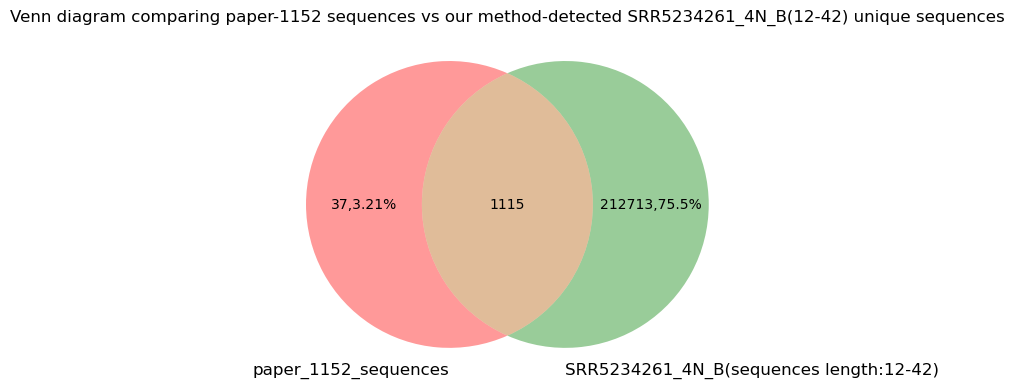

In [ ]:
import matplotlib.pyplot as plt
# from matplotlib_venn import venn2
from matplotlib_venn import venn2_unweighted

plt.figure(figsize=(6, 6))
venn = venn2_unweighted(subsets=("37,3.21%","212713,75.5%","1115")
, set_labels=('paper_1152_sequences', 'SRR5234261_4N_B(sequences length:12-42)'))
# venn.get_patch_by_id('10').set_facecolor("#A5CFEF")
# venn.get_patch_by_id('01').set_facecolor("#C7AEDB")
# venn.get_patch_by_id('11').set_facecolor("#E7A6A6")

plt.title("Venn diagram comparing paper-1152 sequences vs our method-detected SRR5234261_4N_B(12-42) unique sequences")
plt.show()

In [ ]:
from Bio import SeqIO

fastq_file = "data/final_seq_12_SRR5234287_CleanTag.fasta"  # replace with your actual file

lengths = [len(record.seq) for record in SeqIO.parse(fastq_file, "fasta")]

print("Shortest length:", min(lengths))
print("Longest length:", max(lengths))

Shortest length: 12
Longest length: 49


In [ ]:
fastq_file = "data/final_seq_12_SRR5234257_4N_A.fasta"  # replace with your actual file

lengths = [len(record.seq) for record in SeqIO.parse(fastq_file, "fasta")]

print("Shortest length:", min(lengths))
print("Longest length:", max(lengths))

Shortest length: 12
Longest length: 41


In [ ]:
fastq_file = "data/final_seq_12_SRR6380716_NEBNext.fasta"  # replace with your actual file

lengths = [len(record.seq) for record in SeqIO.parse(fastq_file, "fasta")]

print("Shortest length:", min(lengths))
print("Longest length:", max(lengths))

Shortest length: 12
Longest length: 73


In [ ]:
fastq_file = "data/final_seq_12_SRR5234307_TrueSeq.fasta"  # replace with your actual file

lengths = [len(record.seq) for record in SeqIO.parse(fastq_file, "fasta")]

print("Shortest length:", min(lengths))
print("Longest length:", max(lengths))

Shortest length: 12
Longest length: 47


In [ ]:
fastq_file = "data/final_seq_12_SRR5234277_4N_NEXTflex.fasta"  # replace with your actual file

lengths = [len(record.seq) for record in SeqIO.parse(fastq_file, "fasta")]

print("Shortest length:", min(lengths))
print("Longest length:", max(lengths))

Shortest length: 12
Longest length: 939


In [ ]:
from Bio import SeqIO
fastq_file = "data/final_seq_12_SRR5234277_4N_NEXTflex.fasta"  # replace with your actual file

# lengths = [len(record.seq) for record in SeqIO.parse(fastq_file, "fasta")]
top_10_lengths = sorted(lengths, reverse=True)[:1000]
print("Top 10 longest lengths:", top_10_lengths)
# print("Shortest length:", min(lengths))
# print("Longest length:", max(lengths))


Top 10 longest lengths: [939, 927, 801, 653, 645, 598, 591, 521, 445, 428, 421, 409, 405, 403, 399, 391, 383, 374, 372, 364, 363, 357, 355, 355, 349, 344, 341, 339, 333, 329, 326, 326, 326, 324, 322, 322, 321, 315, 313, 311, 310, 307, 306, 306, 304, 304, 303, 302, 301, 296, 294, 294, 294, 293, 293, 290, 287, 286, 282, 280, 277, 276, 276, 275, 274, 273, 272, 272, 269, 269, 268, 268, 264, 262, 262, 260, 259, 257, 257, 257, 257, 256, 256, 255, 254, 254, 254, 253, 251, 250, 250, 248, 248, 246, 243, 242, 242, 240, 237, 237, 232, 231, 231, 229, 229, 226, 223, 223, 222, 220, 218, 218, 217, 213, 212, 210, 205, 205, 204, 204, 203, 203, 203, 203, 202, 202, 202, 201, 200, 200, 199, 199, 198, 198, 197, 194, 194, 193, 193, 193, 193, 193, 192, 192, 191, 191, 191, 190, 190, 189, 189, 189, 187, 186, 186, 186, 186, 186, 185, 185, 184, 183, 182, 182, 182, 181, 180, 180, 179, 177, 177, 177, 177, 176, 175, 174, 174, 172, 172, 172, 171, 170, 170, 170, 169, 169, 169, 169, 168, 168, 167, 167, 167, 166, 166, 